In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
#Define initial parameters
initial_investment = 10000
annual_rate = 0.10
years = 10

In [7]:
#Calculate Simple interest and compound interest
simple_interest_value = initial_investment * (
    1 + annual_rate * years
)

compound_interest_value = initial_investment * (
    1 + annual_rate
) ** years

print(f"Simple Interest Value: ${simple_interest_value:,.2f}")
print(f"Compound Interest Value: ${compound_interest_value:,.2f}")

Simple Interest Value: $20,000.00
Compound Interest Value: $25,937.42


In [8]:
#Visualize investment growth
time = np.arange(0, years + 1)

simple_growth = initial_investment * (
    1 + annual_rate * time
)

compound_growth = initial_investment * (
    1 + annual_rate
) ** time

growth = pd.DataFrame({
    "Year": time,
    "Simple Interest": simple_growth,
    "Compound Interest": compound_growth
})

growth

,Year,Simple Interest,Compound Interest
0,0,10000.0,10000.000000
1,1,11000.0,11000.000000
2,2,12000.0,12100.000000
3,3,13000.0,13310.000000
4,4,14000.0,14641.000000
5,5,15000.0,16105.100000
6,6,16000.0,17715.610000
7,7,17000.0,19487.171000
8,8,18000.0,21435.888100
9,9,19000.0,23579.476910


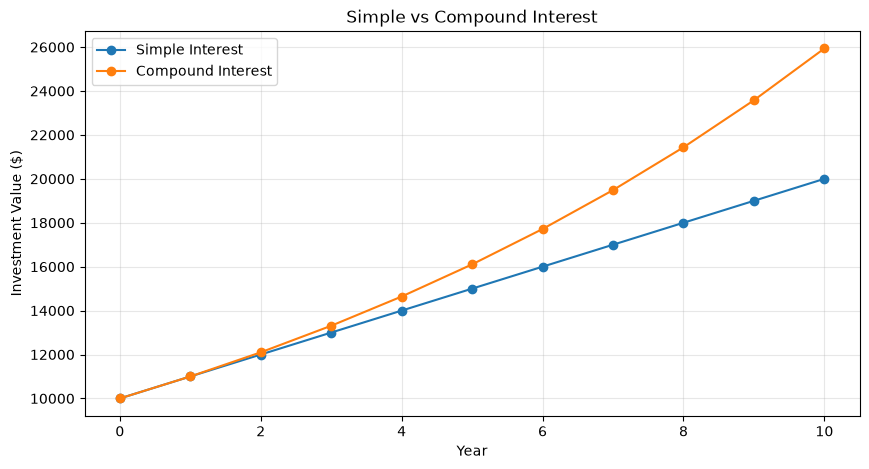

In [9]:
#Plot the results
growth.plot(
    x="Year",
    figsize=(10, 5),
    marker="o"
)

plt.title("Simple vs Compound Interest")
plt.ylabel("Investment Value ($)")
plt.grid(alpha=0.3)
plt.show()

In [11]:
#Implement CAGR
#Creating a CAGR function
def calculate_cagr(initial_value, final_value, years):

    cagr = (final_value / initial_value) ** (1 / years) - 1

    return cagr

In [12]:
#Use the CAGR function

stock_a_cagr = calculate_cagr(100, 200, 5)
stock_b_cagr = calculate_cagr(100, 150, 2)

print(f"Stock A CAGR: {stock_a_cagr:.4%}")
print(f"Stock B CAGR: {stock_b_cagr:.4%}")

Stock A CAGR: 14.8698%
Stock B CAGR: 22.4745%


In [13]:
#Investigate Compounding frequency

principal = 100
rate = 0.10
years = 1

frequencies = np.array([
    1, 2, 4, 12, 52, 365, 8760
])

future_values = principal * (
    1 + rate / frequencies
) ** (frequencies * years)

compounding_results = pd.DataFrame({
    "Frequency": frequencies,
    "Future Value": future_values
})

compounding_results

,Frequency,Future Value
0,1,110.000000
1,2,110.250000
2,4,110.381289
3,12,110.471307
4,52,110.506479
5,365,110.515578
6,8760,110.517029


In [14]:
#Calculate Continuous compounding

continuous_value = principal * np.exp(rate * years)

print(f"Continuous Compounding: ${continuous_value:.6f}")

Continuous Compounding: $110.517092


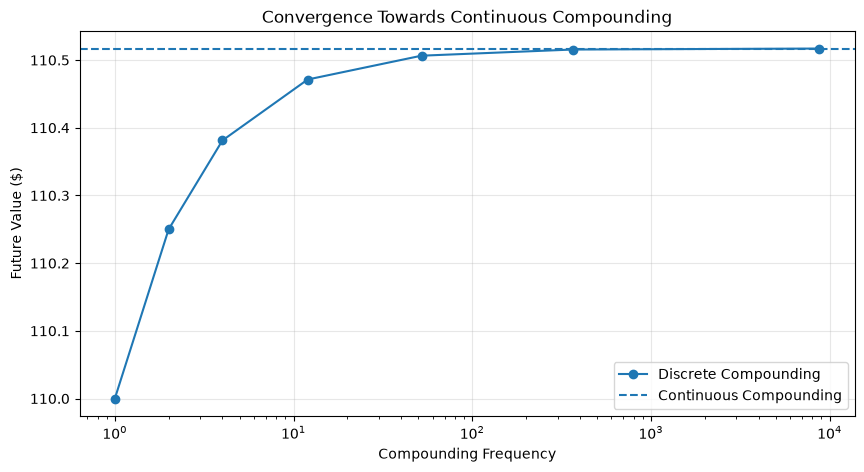

In [15]:
#Compare discrete and continuous compounding

plt.figure(figsize=(10, 5))

plt.plot(
    frequencies,
    future_values,
    marker="o",
    label="Discrete Compounding"
)

plt.axhline(
    continuous_value,
    linestyle="--",
    label="Continuous Compounding"
)

plt.xscale("log")
plt.xlabel("Compounding Frequency")
plt.ylabel("Future Value ($)")
plt.title("Convergence Towards Continuous Compounding")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Assignment A — Calculate investment performance

In [28]:
#Create the database

prices = pd.Series(
    [100, 120, 90, 135, 150, 180],
    index=[2020, 2021, 2022, 2023, 2024, 2025],
    name="Price"
)
prices

2020    100
2021    120
2022     90
2023    135
2024    150
2025    180
Name: Price, dtype: int64

In [29]:
#Calculate cumulative simple return

cumulative_return = (prices.iloc[-1]/prices.iloc[0])-1

print(f"Cumulative Simple Return: {cumulative_return:.2%}")

Cumulative Simple Return: 80.00%


In [33]:
#Calculate CAGR
years = len(prices) - 1

cagr = calculate_cagr(
    prices.iloc[0],
    prices.iloc[-1],
    years
)

print(f"CAGR: {cagr:.2%}")

CAGR: 12.47%


In [34]:
#Calculate cumulative log return
cumulative_log_return = np.log(prices.iloc[-1]/prices.iloc[0])
print(f"Cumulative Log Return: {cumulative_log_return:.2%}")

Cumulative Log Return: 58.78%


In [35]:
# Calculate annualized log return

annualized_log_return = cumulative_log_return / years

print(f"Annualized Log Return: {annualized_log_return:.2%}")

Annualized Log Return: 11.76%


In [37]:
# Convert annualized log return to CAGR

converted_cagr = np.exp(annualized_log_return)-1

print(f"Converted CAGR: {converted_cagr:.4%}")

# Validate against previously calculated CAGR

validation = np.isclose(cagr,converted_cagr)

print(validation)

Converted CAGR: 12.4746%
True


In [42]:
# Model 1: Discrete compounding

final_price_discrete = prices.iloc[0]*(1+cagr)**years

# Model 2: Continuous compounding

final_price_continuous = prices.iloc[0]*np.exp(annualized_log_return*years)

# Print results

print(f"Discrete Model: ${final_price_discrete:.2f}")
print(f"Continuous Model: ${final_price_continuous:.2f}")

# Model validation

validation_1 = np.isclose(final_price_discrete,prices.iloc[-1])

validation_2 = np.isclose(final_price_continuous,prices.iloc[-1])

assert validation_1
assert validation_2

print("All model validation tests passed.")

Discrete Model: $180.00
Continuous Model: $180.00
All model validation tests passed.


In [44]:
effective_annual_return = 0.10

continuous_annual_return = np.log(1 + effective_annual_return)

print(f"Continuous Return: {continuous_annual_return:.4%}")

Continuous Return: 9.5310%


Assignment C — Build a reusable financial function

In [49]:
def calculate_annualized_log_return(
    initial_value,
    final_value,
    years
):
    return np.log(final_value / initial_value) / years

#test the function

result = calculate_annualized_log_return(100, 180, 5)

print(f"Annualized Log Return: {result:.4%}")

Annualized Log Return: 11.7557%


In [56]:
# Calculate returns

test_1 = calculate_annualized_log_return(100, 180, 5)
test_2 = calculate_annualized_log_return(100, 60, 5)
test_3 = calculate_annualized_log_return(100, 100, 5)
test_4 = calculate_annualized_log_return(100, 200, 10)

print(test_1)
print(test_2)
print(test_3)
print(test_4)


0.11755733298042381
-0.10216512475319814
0.0
0.06931471805599453


In [52]:
# Validate results

assert test_1 > 0
assert test_2 < 0
assert np.isclose(test_3, 0)
assert test_4 > 0

print("All function tests passed.")

All function tests passed.


In [57]:
# Numerical accuracy tests

assert np.isclose(test_1, 0.11755733)
assert np.isclose(test_2, -0.10216512)
assert np.isclose(test_3, 0)
assert np.isclose(test_4, 0.0693147180)

print("All numerical accuracy tests passed.")

All numerical accuracy tests passed.


In [ ]:
log_returns = np.log(
    prices / prices.shift(1)
)

log_returns

In [59]:
# Calculate individual annual log returns
log_returns = np.log(prices / prices.shift(1))

# Sum individual log returns
sum_log_returns = log_returns.sum()

# Calculate cumulative log return directly
direct_log_return = np.log(
    prices.iloc[-1] / prices.iloc[0]
)

# Validate time additivity
assert np.isclose(sum_log_returns, direct_log_return)

print(f"Sum of Log Returns: {sum_log_returns:.4%}")
print(f"Direct Log Return: {direct_log_return:.4%}")
print("Time additivity validation passed.")

Sum of Log Returns: 58.7787%
Direct Log Return: 58.7787%
Time additivity validation passed.


In [60]:
mean_log_return = log_returns.mean()

assert np.isclose(mean_log_return, annualized_log_return)

print(f"Mean Log Return: {mean_log_return:.4%}")

Mean Log Return: 11.7557%


#Final formula cheat sheet
#Financial measure	Mathematical formula	Python
#Cumulative simple return	\(P_T/P_0-1\)	prices.iloc[-1]/prices.iloc[0]-1
#Cumulative log return	\(\ln(P_T/P_0)\)	log_returns.sum()
#CAGR	\((P_T/P_0)^{1/T}-1\)	(PT/P0)**(1/T)-1
#Annualized log return	\(\ln(P_T/P_0)/T\)	log_returns.mean()
#Log to effective return	\(e^r-1\)	np.expm1(r)
#Effective to log return	\(\ln(1+R)\)	np.log1p(R)
#Discrete price reconstruction	\(P_0(1+R)^T\)	P0*(1+R)**T
#Continuous price reconstruction	\(P_0e^{rT}\)	P0*np.exp(r*T)

## Research Findings and Conclusion

This study examined the mathematical relationship between cumulative returns, compound annual growth rates (CAGR), and continuously compounded returns using a synthetic five-year equity price dataset.

### Key Findings

1. The investment generated a cumulative simple return of 80%, equivalent to a CAGR of 12.4746%.

2. The annualized continuously compounded return was 11.7557%. Although numerically different from CAGR, both measures represent equivalent investment performance.

3. Discrete and continuous compounding models reconstructed the same terminal investment value of $180 when their respective return conventions were applied.

4. Log returns demonstrated time additivity, whereby the sum of individual periodic log returns equals the cumulative log return.

5. For equally spaced annual observations, the arithmetic mean of individual log returns equals the annualized log return.

### Model Validation

The implementation includes behavioural tests, numerical accuracy tests, return conversion tests, terminal price reconstruction tests, and time additivity validation.

### Investment Implications

CAGR provides an intuitive measure of historical compounded investment performance, while log returns provide mathematical advantages for financial modelling, time-series analysis, and quantitative research.

Neither measure independently captures investment risk, volatility, or the magnitude of interim losses.

### Limitations

The analysis uses synthetic annual stock prices and excludes dividends, transaction costs, taxes, and external cash flows. The results demonstrate mathematical relationships rather than predictive investment performance.